#### Notes on environment activation
source .venv/bin/activate

# Reinforcement Learning project:
## Adaptive optics control with reinforcement learning

In [1]:
!pip install hcipy
import hcipy as hc
import numpy as np
import matplotlib.pyplot as plt
import scipy.ndimage as ndimage
import time
import os
from tqdm.notebook import tqdm

print(hc.__version__)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 242.8/242.8 kB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 971.7/971.7 kB 30.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 105.8/105.8 kB 4.6 MB/s eta 0:00:00
0.7.0


### General parameters

In [ ]:
wavelength_wfs = 842.0E-9 #nm
telescope_diameter = 6.5 #m
# zero_magnitude_flux = 3.9E10
# stellar_magnitude = 0

### Pyramid Wavefront Sensor

In [ ]:
num_pupil_pixels = 70
pupil_grid_diameter = 60/56 * telescope_diameter

#input pupil grid for the P-WFS
pupil_grid = hc.make_pupil_grid(num_pupil_pixels, pupil_grid_diameter)
magellan_aperture = hc.evaluate_supersampled(hc.make_magellan_aperture(), pupil_grid, 6, make_sparse = False) # mak_magellan_aperture() if no arguments telescope diameter is 6.5m. By changing the diameter of the pupil_grid the proportion grid-aperture changes.

# #show input pupil
# hc.imshow_field(magellan_aperture)
# plt.xlabel('x position(m)')
# plt.ylabel('y position(m)')
# plt.colorbar()
# plt.show()


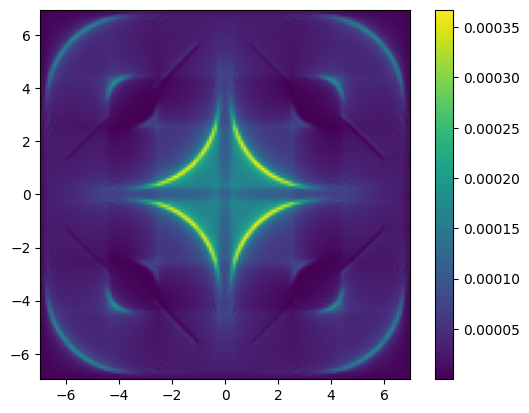

In [ ]:
# output pupil grid for P-WFS
pwfs_grid = hc.make_pupil_grid(140, 2 * pupil_grid_diameter)
pwfs = hc.PyramidWavefrontSensorOptics(pupil_grid, pwfs_grid, separation=pupil_grid_diameter, pupil_diameter=telescope_diameter, wavelength_0=wavelength_wfs, q=3)
camera = hc.NoiselessDetector(pwfs_grid)
wf = hc.Wavefront(magellan_aperture, wavelength_wfs)
wf.total_power = 1

camera.integrate(pwfs.forward(wf), 1)

image_ref = camera.read_out()
image_ref /= image_ref.sum()

hc.imshow_field(image_ref)
plt.colorbar()
plt.show()

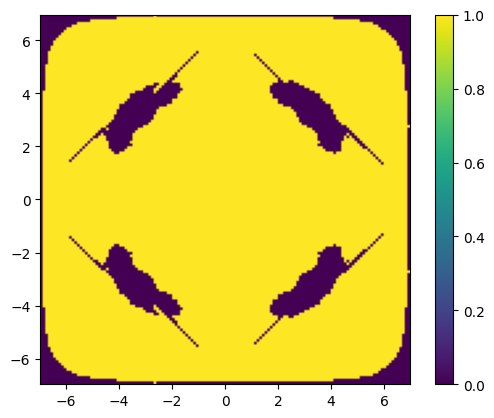

In [ ]:
def pwfs_mask(image, threshold=1.5e-5):
    return image > threshold

mask = pwfs_mask(image_ref)
hc.imshow_field(mask)
plt.colorbar()
plt.show()

In [ ]:
from scipy import ndimage

def build_pwfs_mask(image_ref, pwfs_grid, threshold=0.5e-5, smooth_sigma=2, fill_holes=True):
    """
    Costruisce una maschera robusta per le 4 pupille del PWFS non modulato,
    a partire dall'immagine di riferimento gia' calcolata in AOS.__init__
    (self.image_ref).

    Parametri
    ----------
    image_ref : Field
        Immagine di riferimento (wavefront piatto, gia' normalizzata al
        flusso totale) -- e' self.image_ref nella tua classe AOS.
    pwfs_grid : Grid
        Grid del rivelatore PWFS -- e' self.pwfs_grid nella tua classe AOS.
    threshold : float
        Soglia di flusso per considerare un pixel "dentro" la pupilla.
    smooth_sigma : float
        Sigma del filtro gaussiano applicato PRIMA della soglia, per
        eliminare i falsi buchi dovuti al pattern di diffrazione a croce.
    fill_holes : bool
        Se True, applica un secondo passaggio di fill_holes come rete
        di sicurezza.

    Ritorna
    -------
    mask : Field (booleano)
        Maschera valida, stessa shape di image_ref.
    """
    image_shaped = image_ref.shaped  # torna a griglia 2D (da HCIPy Field a array)

    # 1. Smoothing per eliminare i "baffi" di diffrazione interni
    image_smooth = ndimage.gaussian_filter(image_shaped, sigma=smooth_sigma)

    # 2. Sogliatura sull'immagine smussata, non su quella grezza
    mask = image_smooth > threshold

    # 3. Fill holes come rete di sicurezza (nel caso rimangano buchi residui)
    if fill_holes:
        mask = ndimage.binary_fill_holes(mask)

    # torna a Field (1D) per essere coerente col resto del codice HCIPy
    mask_field = hc.Field(mask.ravel().astype(float), pwfs_grid)

    return mask_field

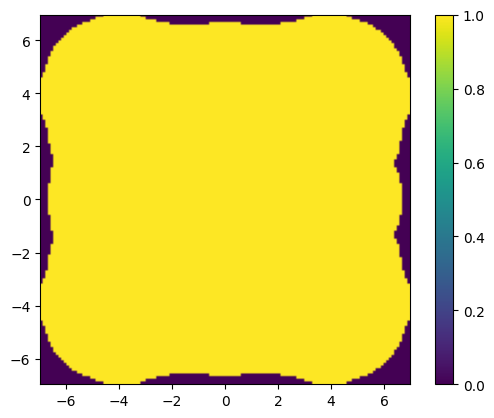

In [ ]:
mask = build_pwfs_mask(image_ref, pwfs_grid, threshold=2.60112e-5, smooth_sigma=2)

hc.imshow_field(mask)
plt.colorbar()
plt.show()

In [ ]:
def build_geometric_pwfs_mask(aperture_function, pupil_grid_diameter, pwfs_grid):
    """
    Costruisce la maschera delle 4 pupille del PWFS per via geometrica,
    replicando l'aperture originale nei 4 centri noti sul pwfs_grid,
    invece di stimarla dall'intensita'.

    Parametri
    ----------
    aperture_function : callable
        La funzione di apertura originale, es. hc.make_magellan_aperture()
        (la stessa usata per costruire self.magellan_aperture).
    pupil_grid_diameter : float
        self.pupil_grid_diameter -- e' anche il valore di 'separation'
        passato a PyramidWavefrontSensorOptics.
    pwfs_grid : Grid
        self.pwfs_grid.

    Ritorna
    -------
    mask : Field (booleano)
    """
    separation = pupil_grid_diameter
    centers = [(+1, +1), (+1, -1), (-1, +1), (-1, -1)]

    mask = pwfs_grid.zeros()

    for sx, sy in centers:
        cx = sx * separation / 2
        cy = sy * separation / 2
        # Sposto il grid (non l'apertura) e ci valuto sopra l'apertura originale
        shifted_grid = pwfs_grid.shifted([-cx, -cy])
        aperture_i = hc.evaluate_supersampled(aperture_function, shifted_grid, 6)
        mask = np.maximum(mask, aperture_i)

    return mask > 0.5

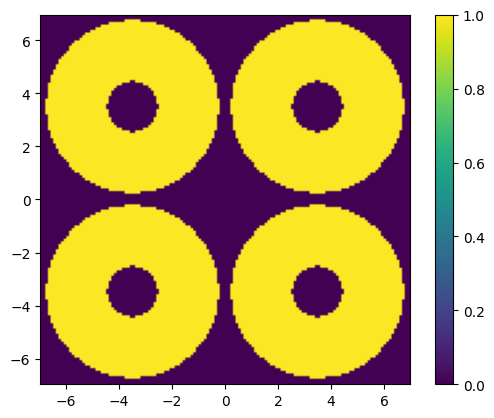

In [ ]:
aperture_function = hc.make_magellan_aperture()  # la stessa usata per self.magellan_aperture
mask = build_geometric_pwfs_mask(aperture_function, pupil_grid_diameter, pwfs_grid)

hc.imshow_field(mask)
plt.colorbar()
plt.show()

###Shack-Hartmann WFS

### Deformable Mirror and Scientific Camera setup

In [ ]:
num_actuators_across_pupil = 20
actuator_spacing = telescope_diameter / num_actuators_across_pupil
print(f'Actuator spacing: {actuator_spacing:.2f} m')
influence_functions = hc.make_gaussian_influence_functions(pupil_grid, num_actuators_across_pupil, actuator_spacing)
influence_functions_dense = influence_functions.to_dense()
print(influence_functions_dense.transformation_matrix.shape)
illuminated_influence_functions = hc.find_illuminated_actuators(influence_functions_dense, magellan_aperture)
print(illuminated_influence_functions.transformation_matrix.shape)
deformable_mirror = hc.DeformableMirror(illuminated_influence_functions)
num_modes = deformable_mirror.num_actuators
print(f'Number of actuators: {num_modes}')

Actuator spacing: 0.33 m
(4900, 400)
(4900, 328)
Number of actuators: 328


In [ ]:
# # from hcipy source code modified output
# def illuminated_actuators_mask(basis, aperture, power_cutoff=0.1):
#     '''Find the illuminated modes.

#     A subset of the modes is selected based on the aperture function and a power cutoff.

#     Parameters
#     ----------
#     basis : ModeBasis
#         The mode basis for which we want to find the illuminated modes.
#     aperture : Field or array_like
#         The aperture
#     power_cutoff : scalar
#         The minimal required power over the aperture.

#     Returns
#     -------
#     mask : ndarray
#         The illuminated influence functions mask.
#     '''
#     total_power = np.sum(abs(basis._transformation_matrix)**2, axis=0)
#     masked_power = np.sum(abs(basis._transformation_matrix[aperture > 0])**2, axis=0)
#     _illuminated_actuator_mask = masked_power >= (power_cutoff * total_power)

#     return  _illuminated_actuator_mask

In [ ]:
# a = illuminated_actuators_mask(influence_functions_dense, magellan_aperture)
# print(np.flip(np.array(a.copy()).reshape(int(np.sqrt(len(a))), int(np.sqrt(len(a)))), axis=0))

In [ ]:
# # Create the interaction matrix starting from mode basis
# probe_amp = 0.01 * wavelength_wfs # actuator amplitude for probing the response of the system (ex. Boston Micromachines DMs have actuators with a total range of motion between 1.5 and 5.5 nm. https://bostonmicromachines.com/products/deformable-mirrors/standard-deformable-mirrors/)
# slopes = []

# wf = hc.Wavefront(magellan_aperture, wavelength_wfs)
# wf.total_power = 1

# for ind in tqdm(range(num_modes)):
#     if ind % 10 == 0:
#         print("Measure response to mode {:d} / {:d}".format(ind+1, num_modes))
#     slope = 0

#     # Probe the phase response
#     for s in [1, -1]:
#         amp = np.zeros((num_modes,))
#         amp[ind] = s * probe_amp
#         deformable_mirror.actuators = amp

#         dm_wf = deformable_mirror.forward(wf)
#         wfs_wf = pwfs.forward(dm_wf)

#         camera.integrate(wfs_wf, 1)
#         image = camera.read_out()
#         image /= np.sum(image)

#         slope += s * (image-image_ref)/(2 * probe_amp) # finite first derivative approximated with central difference method. Variation in PWFS detector image wrt the activation of a piezo electric actuator is the DM.

#     slopes.append(slope)

# slopes = hc.ModeBasis(slopes) # derivatives of PWFS wrt each DM actuator.

In [ ]:
# rcond = 0.08
# reconstruction_matrix = hc.inverse_tikhonov(slopes.transformation_matrix, rcond=rcond, svd=None)

In [ ]:
# # Scientific camera: spatial resolution of the system, focal plane image size and resolution
# spatial_resolution = wavelength_wfs / telescope_diameter #Rayleigh criterion for spatial resolution. The smaller the angle the finer the resolution. The larger the telescope diameter, the better. Assumed f=focallenght=1m
# focal_grid = hc.make_focal_grid(q=8, num_airy=20, spatial_resolution=spatial_resolution)
# prop = hc.FraunhoferPropagator(pupil_grid, focal_grid)
# norm = prop(wf).power.max()

#### Secondary alternative, not important:

In [ ]:
# # --- Alternative response matrix build using slope estimates (pwfse.estimate) ---
# # This cell constructs a response matrix where each column is the slope response
# # to a small poke on each actuator, using the PyramidWavefrontSensorEstimator.
# pwfse = hc.PyramidWavefrontSensorEstimator(magellan_aperture)
# probe_amp = 0.05 * wavelength_wfs  # small poke for linear response
# response_matrix = []
# wf.total_power = 1
# # compute reference slopes from reference image
# slopes_ref = pwfse.estimate(image_ref)

# for i in tqdm(range(num_modes)):
#     if i % 50 == 0:
#         print(f'Measuring slope response for actuator {i+1} / {num_modes}')
#     slope_acc = 0
#     # Probe both signs and form central difference
#     for s in [1, -1]:
#         deformable_mirror.flatten()
#         amps = np.zeros((num_modes,))
#         amps[i] = s * probe_amp
#         deformable_mirror.actuators = amps

#         dm_wf = deformable_mirror.forward(wf)
#         wfs_wf = pwfs.forward(dm_wf)

#         camera.integrate(wfs_wf, 1)
#         image = camera.read_out()
#         image /= np.sum(image)

#         slopes = pwfse.estimate(image)
#         slope_acc += s * (slopes - slopes_ref) / (2 * probe_amp)

#     response_matrix.append(slope_acc.ravel())

# response_matrix = hc.ModeBasis(response_matrix)

In [ ]:
# rcond = 0.05
# reconstruction_matrix = hc.inverse_tikhonov(response_matrix.transformation_matrix, rcond=rcond)
# print('Built reconstruction_matrix from slope-based response (shape):', reconstruction_matrix.shape)

### Atmosphere

In [ ]:
# seeing = 1.2 # arcsec @ 500nm (convention)
# outer_scale =  40  # meter  #40
# tau0 = 0.002 # seconds

# fried_parameter = hc.seeing_to_fried_parameter(seeing)
# Cn_squared = hc.Cn_squared_from_fried_parameter(fried_parameter, 500e-9)
# velocity = 0.314 * fried_parameter / tau0

# print('r0   = {0:.1f}cm'.format(fried_parameter * 100))
# print('L0   = {0:.1f}m'.format(outer_scale))
# print('tau0 = {0:.1f}ms'.format(tau0 * 1000))
# print('v    = {0:.1f}m/s'.format(velocity))
# print('Cn^2 = {0:.1f}'.format(Cn_squared))

r0   = 8.4cm
L0   = 40.0m
tau0 = 2.0ms
v    = 13.2m/s
Cn^2 = 0.0


In [ ]:
# layer = hc.InfiniteAtmosphericLayer(pupil_grid, Cn_squared, outer_scale, velocity= velocity)

# phase_screen_phase = layer.phase_for(wavelength_wfs) # in radian
# phase_screen_opd = phase_screen_phase * (wavelength_wfs / (2 * np.pi)) * 1e6  #optical path difference (mn, that's why we multiply by 1e6). Values are relative delays in the wavefront, not absolute phase values.
# hc.imshow_field(phase_screen_opd, cmap='RdBu')
# plt.colorbar()

In [ ]:
# plt.figure(figsize=(5, 4))
# anim = hc.FFMpegWriter('atmospheric_turbulence.mp4', framerate=5)

# t_end = 1
# n = 51
# for t in np.linspace(0, t_end, n):
#     layer.t = t

#     phase_screen_phase = layer.phase_for(wavelength_wfs) # in radian
#     phase_screen_opd = phase_screen_phase * (wavelength_wfs / (2 * np.pi)) * 1e6 # in um

#     plt.clf()
#     plt.suptitle('Time %.3f s' % t)

#     plt.subplot(1,1,1)
#     plt.title('Turbulent wavefront [$\\mu$m]')
#     hc.imshow_field(phase_screen_opd, vmin=-6, vmax=6, cmap='RdBu')
#     plt.colorbar()

#     anim.add_frame()

# plt.close()
# anim.close()

# # Show created animation
# anim

In [ ]:
# slopes_ref = pwfse.estimate(image_ref)

### Closed loop animation

In [ ]:
# from matplotlib import animation, rc
# from IPython.display import HTML
# import warnings
# warnings.filterwarnings("ignore")

In [ ]:
# # deformable_mirror_atmos = hc.DeformableMirror(influence_functions)
# # deformable_mirror_atmos.random(0.2 * wavelength_wfs)
# layer.reset()
# deformable_mirror.flatten()
# # gain = 0.2
# # leakage = 0
# gain = 0.5
# leakage = 0.05
# num_iterations = 100
# burn_in_iterations = 5
# delta_t = 1E-3

# # coro = PerfectCoronagraph(VLT_aperture, 4)

# long_exposure = focal_grid.zeros()
# # long_exposure_coro = focal_grid.zeros()

# # Set up animation
# plt.figure(figsize=(12, 8))
# anim = hc.FFMpegWriter('AO_simulation_with_turbulence.mp4', framerate=10)

# strehl_list = []

# for timestep in tqdm(range(num_iterations)):
#     layer.t = timestep * delta_t
#     phase_screen_phase = layer.phase_for(wavelength_wfs) # in radian
#     phase_screen_opd = phase_screen_phase * (wavelength_wfs / (2 * np.pi)) * 1e6 # in um


#     # Propagate through atmosphere and deformable mirror.
#     wf_wfs_after_atmos = layer(wf)
#     # wf_wfs_after_atmos = deformable_mirror_atmos(wf) # the DM is part of the atmosphere, so we propagate through the DM and then through the atmosphere. The DM is not in the control loop, it's just a static phase screen that adds to the atmospheric turbulence.
#     wf_wfs_after_dm = deformable_mirror(wf_wfs_after_atmos)

#     # Propagate through P-WFS
#     wf_wfs_on_pwfs = pwfs(wf_wfs_after_dm) #shwfs(magnifier(wf_wfs_after_dm))

#     # Propagate the NIR wavefront
#     #wf_sci_focal_plane = propagator(deformable_mirror(layer(wf_sci)))
#     #wf_sci_coro = propagator(coro(deformable_mirror(layer(wf_sci))))
#     psf = prop(wf_wfs_after_dm).power

#     # Read out WFS camera
#     camera.integrate(wf_wfs_on_pwfs, delta_t)
#     wfs_image = camera.read_out()
#     #wfs_image = hc.large_poisson(wfs_image).astype('float')
#     wfs_image /= np.sum(wfs_image)

#     # # Accumulate long-exposure image
#     if timestep >= burn_in_iterations:
#         long_exposure += psf / (num_iterations - burn_in_iterations)
#     #     long_exposure_coro += wf_sci_coro.power / (num_iterations - burn_in_iterations)

#     # # Calculate slopes from WFS image
#     # slopes = pwfse.estimate(wfs_image)
#     # slopes -= slopes_ref
#     # slopes = slopes.ravel()
#     diff_image = wfs_image - image_ref

#     # # Perform wavefront control and set DM actuators
#     # deformable_mirror.actuators = (1 - leakage) * deformable_mirror.actuators - gain * reconstruction_matrix.dot(slopes)
#     deformable_mirror.actuators = (1-leakage) * deformable_mirror.actuators - gain * reconstruction_matrix.dot(diff_image) # change actuators position in DM. Classic integrator with leakage(perdita).

#     sr = hc.get_strehl_from_focal(psf, prop(wf).power) #current strehl ratio
#     strehl_list.append(sr)

#     if timestep == num_iterations - 1:
#         print(f'___Strehl Ratio over {num_iterations} iterations___')
#         print(f'Average: {np.mean(strehl_list) * 100:.1f}%')
#         print(f'Std: {np.std(strehl_list) * 100:.1f}%')
#         del strehl_list
#         print(f'LE SR: {hc.get_strehl_from_focal(long_exposure, prop(wf).power) * 100:.1f}%')

#     # Plotting
#     if timestep % 20 == 0:
#         plt.clf()

#         plt.suptitle('Timestep %d / %d' % (timestep, num_iterations))

#         plt.subplot(2,3,1)
#         plt.title('DM surface [nm]') #[$\\mu$m]')
#         hc.imshow_field(magellan_aperture * deformable_mirror.surface * 1e9, cmap='RdBu')#, vmin=-1, vmax=1) #, mask=VLT_aperture)
#         plt.colorbar()

#         plt.subplot(2,3,2)
#         plt.title('WFS image [counts]')
#         hc.imshow_field(wfs_image) #, cmap='inferno')
#         plt.colorbar()

#         plt.subplot(2,3,3)
#         plt.title('Instantaneous PSF ($\\mu$m) [log]')
#         # hc.imshow_field(np.log10(wf_sci_focal_plane.power/ wf_sci_focal_plane.power.max()), vmin=-6, vmax=0, cmap='inferno')
#         hc.imshow_field(np.log10(psf / psf.max() * wf_wfs_after_dm.total_power), cmap='inferno')
#         plt.colorbar()

#         if timestep >= burn_in_iterations:
#             plt.subplot(2,3,4)
#             plt.title('Average PSF at 2.2$\\mu$m [log]')
#             hc.imshow_field(np.log10(long_exposure / long_exposure.max()), vmin=-6, vmax=0, cmap='inferno')
#             plt.colorbar()

#         plt.subplot(2,3,5)
#         plt.title('Turbulent wavefront [$\\mu$m]')
#         hc.imshow_field(magellan_aperture * phase_screen_opd, cmap='RdBu')
#         plt.colorbar()

#         print(f'Timestep {timestep}: Strehl ratio = {sr * 100 :.1f}%') # print strehl ratio

#         anim.add_frame()

# plt.close()
# anim.close()

# # Show created animation
# anim


# More compact code

### Command line arguments

In [ ]:
seeing = 1.2 # arcsec @ 500nm (convention)
outer_scale =  40  # larger turbulence diameter, meters
tau0 = 0.002 # temporal coherence, seconds
fried_parameter = hc.seeing_to_fried_parameter(seeing) # r0, spatial coherence, meters
Cn_squared = hc.Cn_squared_from_fried_parameter(fried_parameter, 500e-9)
velocity = 0.314 * fried_parameter / tau0 # wind velocity

print('r0   = {0:.1f}cm'.format(fried_parameter * 100))
print('L0   = {0:.1f}m'.format(outer_scale))
print('tau0 = {0:.1f}ms'.format(tau0 * 1000))
print('v    = {0:.1f}m/s'.format(velocity))
print('Cn^2 = {0:.1f}'.format(Cn_squared))

In [ ]:
import argparse

def create_args():

    parser = argparse.ArgumentParser(description="Adaptive Optics Closed Loop System Initialization and Simulation Parameters")

    # Adaptive Optics system set up
    parser.add_argument("--wavelength_wfs", type=float, default=842.0E-9, help="Wavelength for the wavefront sensor in meters (default: 842.0E-9 nm)")
    parser.add_argument("--telescope_diameter", type=float, default=6.5, help="Diameter of the telescope in meters (default: 6.5 m)")
    parser.add_argument("--num_pupil_pixels", type=int, default=70, help="Number of pixels across the pupil grid (default: 70)")
    parser.add_argument("--num_actuators_across_pupil", type=int, default=5, help="Number of actuators across the pupil (default: 40)")
    parser.add_argument("--rcond", type=float, default=0.08, help="Regularization condition number for Tikhonov inversion (default: 0.08)")
    parser.add_argument("--seeing", type=float, default=1.2, help="Seeing in arcseconds at 500nm (default: 1.2 arcsec)")
    parser.add_argument("--outer_scale", type=float, default=40, help="Outer scale of turbulence in meters (default: 40 m)")
    parser.add_argument("--tau0", type=float, default=0.002, help="Coherence time of turbulence in seconds (default: 0.002 s)")
    parser.add_argument("--prob_amp_coeff", type=float, default=0.01, help="Coefficient for actuator amplitude probing (default: 0.01)")

    # closed loop episode simulation
    parser.add_argument("--gain", type=float, default=0.5, help="Gain for the closed loop control (default: 0.5)")
    parser.add_argument("--leakage", type=float, default=0.05, help="Leakage for the closed loop control (default: 0.05)")
    parser.add_argument("--num_iterations", type=int, default=100, help="Number of iterations for the closed loop simulation (default: 100)")
    parser.add_argument("--burn_in_iterations", type=int, default=5, help="Number of burn-in iterations before accumulating long-exposure image (default: 5)")
    parser.add_argument("--delta_t", type=float, default=1E-3, help="Time step for each iteration in seconds (default: 1E-3 s)")

    # SAC parameters
    parser.add_argument("--gamma", type=float, default=0.99, help="Discount factor for SAC (default: 0.99)")
    parser.add_argument("--tau", type=float, default=0.005, help="Soft update coefficient for target networks in SAC (default: 0.005)")
    parser.add_argument("--replay_pool_size", type=int, default=int(1e6), help="Size of the replay pool for SAC (default: 1000000)")
    parser.add_argument("--episodes", type=int, default=10, help="Number of episodes for SAC (default: 10)")
    parser.add_argument("--episode_steps", type=int, default=20, help="Number of steps per episode for SAC (default: 100)")
    parser.add_argument("--warm_up_steps", type=int, default=20, help="Number of warmup steps for SAC (default: 1000)")
    parser.add_argument("--env_steps", type=int, default=100, help="Number of steps in the environment for SAC (default: 1000)")
    parser.add_argument("--gradient_steps", type=int, default=100, help="Number of gradient steps for SAC (default: 100)")
    parser.add_argument("--actor_lr", type=float, default=1e-4, help="Learning rate for the actor (default: 1e-4)")
    parser.add_argument("--critic_lr", type=float, default=1e-4, help="Learning rate for the critic (default: 1e-4)")
    parser.add_argument("--alpha_lr", type=float, default=1e-4, help="Learning rate for the temperature parameter alpha (default: 1e-4)")
    parser.add_argument("--batch_size", type=int, default=40, help="Batch size for gradient steps (default: 40)")
    parser.add_argument("--minibatch_size", type=int, default=10, help="Minibatch size for gradient steps (default: 10)")

    # System with learned policy
    parser.add_argument("--system_steps", type=int, default=100, help="Number of steps of AO system ran with reinforcement learning (default: 100)")

    args, _ = parser.parse_known_args()

    return args

args = create_args()

### Closed loop function (no animation)

In [ ]:
from collections import deque

In [ ]:
class AOS(): #adaptive optics system
    """
    Initialize
    Compute construction matrix
    and iterate over time to collect new states
    """


    def __init__(self, args):
        # pupil
        self.telescope_diameter = args.telescope_diameter #m
        self.num_pupil_pixels = args.num_pupil_pixels
        self.pupil_grid_diameter = 60/56 * self.telescope_diameter
        self.pupil_grid = hc.make_pupil_grid(self.num_pupil_pixels, self.pupil_grid_diameter) #generates a simple Cartesian Grid with pixel and reference physical dimensions as stated in the parameters.
        self.magellan_aperture = hc.evaluate_supersampled(hc.make_magellan_aperture(), self.pupil_grid, 6) # mak_magellan_aperture() if no arguments telescope diameter is 6.5m. By changing the diameter of the pupil_grid the proportion grid-aperture changes.

        # Point Spread Function
        self.wavelength_wfs = args.wavelength_wfs
        self.wf = hc.Wavefront(self.magellan_aperture, self.wavelength_wfs) #ELECTRIC FIELD (physical, lots of attributes) on a PLANE (distance from source is irrelevant), a photography of its properties.
        self.wf.total_power = 1 # normalization

        # atmospheric layer
        self.seeing = args.seeing # arcsec @ 500nm (convention)
        self.outer_scale = args.outer_scale    # meter  #40
        self.tau0 = args.tau0 # seconds
        self.fried_parameter = hc.seeing_to_fried_parameter(self.seeing)
        self.Cn_squared = hc.Cn_squared_from_fried_parameter(self.fried_parameter, 500e-9)
        self.velocity = 0.314 * self.fried_parameter / self.tau0
        self.layer = hc.InfiniteAtmosphericLayer(self.pupil_grid, self.Cn_squared, self.outer_scale, velocity= self.velocity)

        # deformable mirror
        self.num_actuators_across_pupil = args.num_actuators_across_pupil
        self.actuator_spacing = self.telescope_diameter / self.num_actuators_across_pupil
        self.influence_functions = hc.make_gaussian_influence_functions(self.pupil_grid, self.num_actuators_across_pupil, self.actuator_spacing)
        self.deformable_mirror = hc.DeformableMirror(self.influence_functions)
        self.num_modes = self.deformable_mirror.num_actuators
        self.prob_amp = args.prob_amp_coeff * self.wavelength_wfs # actuator amplitude for probing the response of the system (ex. Boston Micromachines DMs have actuators with a total range of motion between 1.5 and 5.5 nm. https://bostonmicromachines.com/products/deformable-mirrors/standard-deformable-mirrors/)

        # pyramid wavefront sensor
        self.pwfs_grid = hc.make_pupil_grid(140, 2 * self.pupil_grid_diameter)
        self.pwfs = hc.PyramidWavefrontSensorOptics(self.pupil_grid, self.pwfs_grid, separation=self.pupil_grid_diameter, pupil_diameter=self.telescope_diameter, wavelength_0=self.wavelength_wfs, q=3)
        self.camera = hc.NoiselessDetector(self.pwfs_grid)
        self.camera.integrate(self.pwfs.forward(self.wf), 1)
        self.image_ref = self.camera.read_out()
        self.image_ref /= self.image_ref.sum()

        # Scientific camera: spatial resolution of the system, focal plane image size and resolution
        self.spatial_resolution = self.wavelength_wfs / self.telescope_diameter #Rayleigh criterion for spatial resolution. The smaller the angle the finer the resolution. The larger the telescope diameter, the better. Assumed f=focallenght=1m
        self.focal_grid = hc.make_focal_grid(q=8, num_airy=20, spatial_resolution=self.spatial_resolution)
        self.prop = hc.FraunhoferPropagator(self.pupil_grid, self.focal_grid)
        self.norm = self.prop(self.wf).power.max()


        # reconstruction matrix and history
        self.reconstruction_matrix = None
        self.compute_interaction_matrix(args)

        # iteration
        self.max_iterations = args.num_iterations
        self.gain = args.gain
        self.leakage = args.leakage
        self.burn_in_iterations = args.burn_in_iterations
        self.delta_t = args.delta_t
        self.long_exposure = self.focal_grid.zeros()
        self.strehl_list = []
        self.timestep = 0
        self.psf = None

        # # action
        # self._action = np.zeros((self.deformable_mirror.num_actuators)) # action is the command to the DM actuators. It is a vector of length num_actuators_across_pupil^2, which is the number of actuators in the DM. The action is added to the current state of the DM actuators to update their positions.

        # actuators commands
        self.commands = [np.zeros((self.num_modes)), np.zeros((self.num_modes)), np.zeros((self.num_modes))] # a FIFO queue of past 3 actuators commands, most recent ones are added on the right

        # reconstruction
        self.reconstruction = np.zeros((self.num_modes)) # reconstruction of the wavefront from the slopes. Current[0] and future state[1] (= reward) reconstructions.

    # # action setter for shape check (define action as a property and then define a setter for it)
    # #@property
    # def action(self):
    #     return self._action

    # @action.setter
    # def action(self, value):
    #     arr = np.array(value, copy=True)
    #     if arr.shape != (self.deformable_mirror.num_actuators,):
    #         raise ValueError("Invalid action shape, must be the number of actuators: {}".format(self.deformable_mirror.num_actuators))
    #     self._action = arr

    #utils function for creating interaction matrix between sensor-mirror
    def compute_interaction_matrix(self, args):
        """
        Computes and saves the interaction matrix between the deformable mirror
        and the pyramid wavefront sensor. The interaction matrix is computed by probing
        each actuator of the deformable mirror and measuring the response on the wavefront sensor.
        The resulting slopes are used to compute the reconstruction matrix using Tikhonov
        regularization.
        """

        # Create the interaction matrix starting from mode basis
        slopes = []

        for ind in tqdm(range(self.num_modes)):
            # if ind % 10 == 0:
            #     print("Measure response to mode {:d} / {:d}".format(ind+1, self.num_modes))
            slope = 0

            # Probe the phase response
            for s in [1, -1]:
                amp = np.zeros((self.num_modes,))
                amp[ind] = s * self.prob_amp
                self.deformable_mirror.actuators = amp

                dm_wf = self.deformable_mirror.forward(self.wf)
                wfs_wf = self.pwfs.forward(dm_wf)

                self.camera.integrate(wfs_wf, 1)
                image = self.camera.read_out()
                image /= np.sum(image)

                slope += s * (image-self.image_ref)/(2 * self.prob_amp) # finite first derivative approximated with central difference method. Variation in PWFS detector image wrt the activation of a piezo electric actuator is the DM.

            slopes.append(slope)

        slopes = hc.ModeBasis(slopes) # derivatives of PWFS wrt each DM actuator.
        self.reconstruction_matrix = hc.inverse_tikhonov(slopes.transformation_matrix, rcond=args.rcond, svd=None)


    def reset(self):
        """
        Reset the adaptive optics system to its initial state
        """
        self.layer.reset()
        self.deformable_mirror.flatten()
        self.long_exposure = self.focal_grid.zeros()
        self.strehl_list = []
        self.timestep = 0
        self.commands = [np.zeros((self.num_modes)), np.zeros((self.num_modes)), np.zeros((self.num_modes))]
        self._action = np.zeros((self.deformable_mirror.num_actuators))
        self.reconstruction = np.zeros((self.num_modes))
        self.psf = None

        return self

    def compute_reconstruction(self):
        """
        Returns the current wavefront reconstruction from the slopes.
        """
        # update time for the atmospheric layer
        self.layer.t = self.timestep * self.delta_t

        # Propagate through atmosphere and deformable mirror (both changing attributes during iterations)
        wf_wfs_after_atmos = self.layer(self.wf)
        wf_wfs_after_dm = self.deformable_mirror(wf_wfs_after_atmos)

        # Propagate through P-WFS
        wf_wfs_on_pwfs = self.pwfs(wf_wfs_after_dm)

        # Propagate the wavefront
        self.psf = self.prop(wf_wfs_after_dm).power

        # Read out WFS camera
        self.camera.integrate(wf_wfs_on_pwfs, self.delta_t)
        wfs_image = self.camera.read_out()
        wfs_image /= np.sum(wfs_image)

        # Accumulate long-exposure image
        if self.timestep >= self.burn_in_iterations:
            self.long_exposure += self.psf / (self.timestep + 1 - self.burn_in_iterations)

        # Calculate slopes from WFS image
        diff_image = wfs_image - self.image_ref

        # Perform wavefront control and set DM actuators
        self.reconstruction = (self.reconstruction_matrix.dot(diff_image)) # reconstruction of the wavefront from the slopes.

        self.timestep += 1

    # def __iter__(self):
    #     return self

    # def __next__(self):
    #     """
    #     AOS step function to propagate the wavefront through the atmosphere, deformable mirror,
    #     and pyramid wavefront sensor, and compute the current wavefront reconstruction.
    #     """
    #     if self.max_iterations is not None and self.timestep >= self.max_iterations:
    #         raise StopIteration
    #     self.compute_reconstruction()

    #     self.timestep += 1

    #     return self.reconstruction

    def apply_DM_command(self,action=None):
        """
        Compute and apply command to update the DM actuators based on the current reconstruction and action.
        And statistics of the current state of the system (strehl and long exposure strehl ratios).
        This function should be called after each iteration of the closed loop simulation.
        """
        # change actuators position in DM. Classic integrator with leakage(perdita).
        if action is None:
            action = np.zeros((self.deformable_mirror.num_actuators))

        self.deformable_mirror.actuators = (1-self.leakage) * self.deformable_mirror.actuators - self.gain * self.reconstruction + action
        # updating state queue
        if len(self.commands) >= 3:
            self.commands.pop(0)
        self.commands.append(self.deformable_mirror.actuators.copy())

        sr = hc.get_strehl_from_focal(self.psf, self.prop(self.wf).power) #current strehl ratio
        self.strehl_list.append(sr)

        # Plotting
        if (self.timestep) % 100 == 0:
            print(f'___Strehl Ratio over {self.timestep} iterations___')
            print(f'Average: {np.mean(self.strehl_list) * 100:.1f}%')
            print(f'Std: {np.std(self.strehl_list) * 100:.1f}%')
            print(f'LE SR: {hc.get_strehl_from_focal(self.long_exposure, self.prop(self.wf).power) * 100:.1f}%')


    def closed_loop_step_anim():
        pass


In [ ]:
# env = AOS(args)
# env.compute_interaction_matrix(args)
# env_ = iter(env)
# for timestep in range(3):
#     next(env_)
#     state = np.array(env.state[0])
#     print(state[:5])  # Print the first 5 actuator commands of the current state

### Control with Reinforcement Learning

In [ ]:
# Actor: policy function
import torch
import torch.nn as nn
from torch import Tensor
from typing import Optional, Tuple
from torch.distributions import Normal

The actor parametrizes the policy function. It takes the state as input and outputs a multivariated normal distribution (of independent variables) over the action space, from which the final action is then sampled.
The critic ... .

In [ ]:
@torch.no_grad()  # of course we don't want the initialization to be tracked by the computational graph.
def weights_init_(m: nn.Module) -> None:
    if isinstance(m, (nn.Conv2d, nn.Linear)):
        nn.init.kaiming_normal_(m.weight, nonlinearity="relu") # better for networks using ReLu activation functions (https://www.geeksforgeeks.org/python/select-the-right-weight-for-deep-neural-network-in-pytorch/)
        if m.bias is not None:
            nn.init.zeros_(m.bias)

In [ ]:
# Actor: policy function
class Actor(nn.Module):
    """
    Simple spatial actor taking the state as input and returning the (!!!) normalized action (components in [-1,1]) and its log probability.
    """

    def __init__(self, in_channels: int = 4, hidden_dim: int = 64, num_layers: int = 2, kernel_size: int = 3, eps: float = 1e-8, probe_amp: float = 5e-9) -> None:
        """
        Parameters:
        -----------
        in_channels: int
            Number of input channels (default: 4).
        hidden_dim: int
            Number of hidden channels (default: 64).
        num_layers: int
            Number of hidden convolutional layers apart from means and std level (default: 2).
        kernel_size: int
            Size of the convolutional kernels (default: 3x3).
        eps: float
            Small value to prevent numerical issues (default: 1e-8).
        probe_amp: float
            Actuators amplitude probe (default: 5e-9).
        """
        super().__init__()
        padding = 1
        self.eps = eps #again useful for numerical stability
        self.probe_amp = probe_amp # amplitude of the probe

        # activation function
        self.act = nn.ReLU()

        # layers
        self.layers = nn.ModuleList()

        #first hidden layer
        self.layers.append(nn.Conv2d(in_channels, hidden_dim, kernel_size=kernel_size, padding=padding))
        #2nd to nth hidden layers
        for _ in range(num_layers -1 ):
            self.layers.append(nn.Conv2d(hidden_dim, hidden_dim, kernel_size=kernel_size, padding=padding))
        #last level layers
        self.mean_lay = nn.Conv2d(hidden_dim, 1, kernel_size=kernel_size, padding=padding)
        self.log_std_lay = nn.Conv2d(hidden_dim, 1, kernel_size=kernel_size, padding=padding)


        #initialize weights
        self.apply(weights_init_)
        nn.init.zeros_(self.mean_lay.weight)
        nn.init.zeros_(self.log_std_lay.weight)

        self.mean = None
        self.log_std = None


    def forward(self, x: Tensor) -> Tensor:
        """
        Input: (Bsz, 4channels, sqrt(num actuators), sqrt(num actuators)) state tensor.
        Output: (Bsz, 1, sqrt(num actuators), sqrt(num actuators)) mean and log_std tensors.
        """
        for conv in self.layers:
            x = conv(x)

            x = self.act(x)

        #output
        self.mean = self.mean_lay(x)
        self.log_std = self.log_std_lay(x)
        self.log_std = torch.clamp(self.log_std, -20, 2) # clamp log_std to prevent numerical issues with very small or large standard deviations

        return self.mean, self.log_std


    def sample(self, state) -> Tensor:
        """
        Sample an action from the policy distribution and scale it to the range of DM actuator influence.

        Output:
        ---------
        action :
            (Bsz, 1, sqrt(num actuators), sqrt(num actuators)) actions tensor (for each actuator)
        log_prob :
            (Bsz, 1, sqrt(num actuators), sqrt(num actuators)) log probabilities tensor (for each actuator)

        """
        #forward pass
        mean, log_std = self.forward(state)

        # back to std
        std = log_std.exp()

        #sampling of a 2D map action for each batch
        normal = Normal(mean, std)
        sample = normal.rsample()

        # clamp action to [-1,1]
        action = torch.tanh(sample) # scale action to the range of DM actuator influence (nm). The output of the network is in the range [-probe_amp, probe_amp], which is the range of motion for the DM actuators. This ensures that the actions taken by the policy are within the physical limits of the DM.

        # independent action components log prob
        log_prob = normal.log_prob(sample)
        # change of variable of a probability density function
        log_prob -= torch.log(1 - action.pow(2).clamp(min=0, max=1) + self.eps) #action.pow(2) could be slightly larger than 1 due to numerical issues, so we clamp it to 1. eps is added to prevent log(0)
        # # log prob of action (sum of log probabilities of independent components)
        # log_prob = log_prob.sum((2,3), keepdim=False)  # reduce tensor to (Bsz, 1) to have 1 log_prob scalar value per batch.

        # clamp action to the physical range of DM actuators (nm) (rescaling postponed to the time of actual application of the command to the actuators)
        prob_amp = args.prob_amp_coeff * args.wavelength_wfs # scale action to the range of DM actuator influence (nm). The output of the network is in the range [-probe_amp, probe_amp], which is the range of motion for the DM actuators. This ensures that the actions taken by the policy are within the physical limits of the DM.
        action = action * (prob_amp)

        #-------------------------
        # STILL MISSING:
        # actuators masking
        #-------------------------

        return action, log_prob

In [ ]:
# Critic: state value function Q
class Critic(nn.Module):
    """
    Simple critic taking the state and action as input and returning the state-action value as output.
    """

    def __init__(self, in_channels: int = 4, action_channels: int = 1, hidden_dim: int = 64, num_layers: int = 2, kernel_size: int = 3) -> None:
        """
        Parameters:
        -----------
        in_channels: int
            Number of input channels (default: 4).
        action_channels: int
            Number of action channels (default: 1).
        hidden_dim: int
            Number of hidden channels (default: 64).
        num_layers: int
            Number of hidden convolutional layers (default: 3).
        kernel_size: int
            Size of the convolutional kernels (default: 3x3).
        """
        super().__init__()
        padding = 1

        # activation function
        self.act = nn.ReLU()

        # layers
        self.layers = nn.ModuleList()
        self.layers2 = nn.ModuleList()

        #first hidden layer
        self.layers.append(nn.Conv2d(in_channels + action_channels, hidden_dim, kernel_size=kernel_size, padding=padding))
        self.layers2.append(nn.Conv2d(in_channels + action_channels, hidden_dim, kernel_size=kernel_size, padding=padding))
        #2nd to last hidden layers
        for _ in range(num_layers-1):
            self.layers.append(nn.Conv2d(hidden_dim, hidden_dim, kernel_size=kernel_size, padding=padding))
            self.layers2.append(nn.Conv2d(hidden_dim, hidden_dim, kernel_size=kernel_size, padding=padding))
        # output layer
        self.layers.append(nn.Conv2d(hidden_dim, 1, kernel_size=kernel_size, padding=padding))
        self.layers2.append(nn.Conv2d(hidden_dim, 1, kernel_size=kernel_size, padding=padding))

        self.apply(weights_init_)


    def forward(self, state: Tensor, action: Tensor) -> Tensor:
        """
        Inputs:
        ----------
        state: tensor
            (Bsz, 4channels, sqrt(num actuators), sqrt(num actuators))
        action: tensor
            (Bsz, 4channels, sqrt(num actuators), sqrt(num actuators))

        Outputs:
        ----------
        q1: tensor
            (Bsz, 1, sqrt(num actuators), sqrt(num actuators)) state-action value for the first critic
        q2: tensor
            (Bsz, 1, sqrt(num actuators), sqrt(num actuators)) state-action value for the second critic
        """
        x = torch.cat([state, action], dim=1)
        q1 = x.clone()
        q2 = x.clone()

        # first critic
        for layer in self.layers[:-1]:
            q1 = self.act(layer(q1))
        q1 = self.layers[-1](q1)

        # second critic
        for layer in self.layers2[:-1]:
            q2 = self.act(layer(q2))
        q2 = self.layers2[-1](q2)

        return q1, q2 #2 critic output, the min will be taken to avoid policy positive bias, i.e. to overestimate policy value.


To build the target critic: we generate the critic instance and the target critic instance, and consequently we copy the former weights to the latter. The target critic is then updated with a soft update, which is a weighted average of the target critic and the critic weights.

In [ ]:
# target critic (output two Q, then to be compared to extract the min)

### Utils: replay pool

In [ ]:
import itertools as it

class ReplayPool:
    def __init__(self, max_size: int = 10e6) -> None:
        self.max_size = int(max_size)
        self.storage = []

    def append(self, item): # item must be a tuple of (state, action, reward, next_state)
        if len(self.storage) >= self.max_size:
            self.storage.pop(0)
        #check if item is a tuple of length 4
        if not isinstance(item, tuple) or len(item) != 4:
            raise ValueError("Item must be a tuple of (state, action, reward, next_state)")
        self.storage.append(item)

    # def __len__(self):
    #     return len(self.storage)

    # def __getitem__(self, idx):
    #     return [self.storage[int(i)] for i in idx]

    def sample_batch(self, batch_size:int):
        if batch_size > len(self.storage):
            raise ValueError("batch_size larger than replay size")

        indexes = np.random.choice(
            len(self.storage),
            size=batch_size,
            replace=False
        )

        return indexes

    def format_batch(self, indexes):
        batch = [self.storage[i] for i in indexes]

        states, actions, rewards, next_states = zip(*batch)

        states = np.stack(states)
        actions = np.stack(actions)
        rewards = np.stack(rewards)
        next_states = np.stack(next_states)

        return states, actions, rewards, next_states

    def sample_batch_iterator(
                        self,
                        batch_size: int,
                        minibatch_size: int,
                        drop_last: bool = False):

        indexes = self.sample_batch(batch_size)

        for i in range(0, len(indexes), minibatch_size):
            minibatch_indexes = indexes[i:i + minibatch_size]

            if drop_last and len(minibatch_indexes) < minibatch_size:
                continue

            yield self.format_batch(minibatch_indexes)

    #for manual management of last elements in case of wrong append
    def pop(self):
        return self.storage.pop()

In [ ]:
# import itertools as it

# a = range(9)
# print(a)

# for i in it.batched(a, 3):
#     print(i)

In [ ]:
# # init environment and start iterator
# env = AOS(args)

In [ ]:
# print(env.deformable_mirror.actuators.shape)
# array = [i for i in range(9)]
# array = np.array(array)
# print(array)
# sqrt = np.sqrt(array.size)
# matrix = array.reshape(int(sqrt), int(sqrt))
# matrix = np.flip(matrix, axis=0)
# print(matrix)
# print(matrix.shape)


In [ ]:
# #init actor
# actor = Actor()

# # init critic
# critic = Critic()

# # init target critic
# target_critic = Critic()
# target_critic.load_state_dict(critic.state_dict()) # copy weights from critic to target critic

# # init alpha, temperature coefficient for entropy regularization in SAC.
# alpha = torch.tensor(0.0, requires_grad=True)

# #init replay pool
# replay = ReplayPool(max_size=100)

In [ ]:
# # environment loop
# warm_up_steps = 6
# iterations = 50

# pending_state = None
# pending_action = None

# for timestep in range(iterations):
#     # not saving in replay pool
#     if timestep < warm_up_steps:
#         env.compute_reconstruction() # compute and append current reconstruction to reconstruction deque
#         env.apply_DM_command() # compute and append current command to commands deque
#         continue

#     # saving in replay pool
#     # reconstruction_t
#     env.compute_reconstruction()
#     rec = np.flip(np.array(env.reconstruction.copy()).reshape(int(np.sqrt(len(env.reconstruction))), int(np.sqrt(len(env.reconstruction)))), axis=0)


#     # state_t
#     commands = [np.flip(np.array(i).reshape(int(np.sqrt(len(i))), int(np.sqrt(len(i)))), axis=0) for i in env.commands]  # Reshape each command to (num_modes, num_modes)
#     state = np.concatenate((np.array(commands), rec[np.newaxis, :, :]), axis=0)  # Add current reconstruction to the commands array

#     # print state shape before converting to tensor
#     # print(f"State shape before tensor conversion: {state.shape}")  # Print the shape of the state array
#     state = torch.tensor(state, dtype=torch.float32).unsqueeze(0) # Add batch and channel dimensions
#     # print(f"State shape: {state.shape}")  # Print the shape of the state tensor


#     # action_t
#     actor.eval()
#     act, _ = actor.sample(state)
#     act = act.detach().numpy().squeeze()
#     #print(f"Action shape: {act.shape}")  # Print the shape of the action tensor
#     env.action = act
#     # command_t
#     env.apply_DM_command()

#     # replay pool tuple for previous timestep (t-1)
#     if pending_state is not None and pending_action is not None:
#         replay.append((pending_state, pending_action, rec, state))

#     # pending state_t and action_t
#     pending_state = state
#     pending_action = act

# #print(f"Replay pool size: {len(replay)}")  # Print the size of the replay pool

### Dataset

In [ ]:
# def minibatch_to_torch(states, actions, rewards, next_states):
#     """
#     Turns numpy arrays into torch tensors and reshapes them to the correct dimensions for the SAC algorithm
#     """
#     # print(f"States shape: {states.shape}")  # Print the shape of the states array
#     # print(f"Actions shape: {actions.shape}")  # Print the shape of the actions array
#     # print(f"Rewards shape: {rewards.shape}")  # Print the shape of the rewards array
#     # print(f"Next states shape: {next_states.shape}")  # Print the shape of the next states array
#     # print(f"First element of rewards shape: {rewards[0].shape}")  # Print the shape of the first element of the rewards array
#     # print(f"first element of action shape: {actions[0].shape}")  # Print the shape of the first element of the actions array

#     # by default tensors created from numpy arrays have requires_grad=False
#     next_states = torch.as_tensor(next_states).squeeze()
#     actions = torch.as_tensor(actions).unsqueeze(1)
#     states = torch.as_tensor(states).squeeze()
#     rewards = torch.as_tensor(rewards).unsqueeze(1)

#     return states, actions, rewards, next_states


In [ ]:
# next_states = torch.as_tensor(next_states).squeeze()
# with torch.no_grad():
#     next_action, next_log_pi = actor.sample(next_states)

# print(next_action.shape)
# print(next_log_pi.shape)

In [ ]:
# actions = torch.as_tensor(actions).unsqueeze(1)
# states = torch.as_tensor(states).squeeze()

# print(actions.shape, states.shape)

In [ ]:
# qvalues = torch.min(critic(states, actions))
# print(qvalues.shape)

In [ ]:
# qvalues_target = torch.min(target_critic(next_states, next_action))
# print(qvalues_target.shape)

### Update Losses

In [ ]:
# import torch.optim as optim
# actor_optim = optim.Adam(actor.parameters())
# critic_optim = optim.Adam(critic.parameters())
# alpha_optim = optim.Adam([alpha])

In [ ]:
"""
Update section

1. from D collect a batch of data

2. critic update
    batch:
        state, actions from D to compute qvalue,
        reward from D
        next state from D
        next action and next log_pi from current actor evaluated in next state, for qvalue_target and log_pi
        qvalue from critic evaluated in action and state
        qvalue_target from target critic evaluated in next action and next state
    compute loss with targetQ and pi in eval mode and Q in train mode
    set the optimizer which will perform the gradient descent following a specific algorithm
    go backward on the loss and take a gradient descent step

3. actor update (consider alpha fixed)
    batch:
        state from D
        action and log_pi from actor in train mode (???)
        qvalue from critic with parameters action and state
    compute loss with Q in eval mode and pi in train mode
    optimizer
    bacward
    step

4. alpha update
    batch:
        current alpha
        log_pi from actor
        target entropy
    set target entropy somewhere!
    compute loss
    optimizer
    backward
    step

5. target Q update
    compute weighted mean of target and Q weights
"""

'\nUpdate section \n\n1. from D collect a batch of data\n\n2. critic update \n    batch: \n        state, actions from D to compute qvalue, \n        reward from D\n        next state from D \n        next action and next log_pi from current actor evaluated in next state, for qvalue_target and log_pi \n        qvalue from critic evaluated in action and state\n        qvalue_target from target critic evaluated in next action and next state\n    compute loss with targetQ and pi in eval mode and Q in train mode\n    set the optimizer which will perform the gradient descent following a specific algorithm\n    go backward on the loss and take a gradient descent step\n\n3. actor update (consider alpha fixed)\n    batch: \n        state from D \n        action and log_pi from actor in train mode (???)\n        qvalue from critic with parameters action and state\n    compute loss with Q in eval mode and pi in train mode\n    optimizer\n    bacward \n    step\n\n4. alpha update\n    batch: \n  

In [ ]:
# # critic loss
# def compute_critic_loss(qvalues, qvalues_target, rewards, alpha, next_log_pi, gamma):
#     loss = 0.5 * (qvalues - (rewards + torch.mul(gamma, qvalues_target) - torch.mul(alpha, next_log_pi))).pow(2)
#     loss = loss.mean()

#     return loss

# # update critic
# def update_critic(
#         states, actions, rewards, next_states, alpha, gamma=args.gamma
#         ):

#     alpha = alpha.detach()
#     with torch.no_grad():
#         next_actions, next_log_pi = actor.sample(next_states)
#         qvalues1_target, qvalues2_target = target_critic(next_states, next_actions)
#         qvalues_target = torch.min(qvalues1_target, qvalues2_target)

#     qvalues1, qvalues2 = critic(states, actions)
#     qvalues = torch.min(qvalues1, qvalues2)

#     # print(f"next_action {next_actions.shape}, \n next_log_pi {next_log_pi.shape}, \n qvalues1_target {qvalues1_target.shape}, \n qvalues2_target {qvalues2_target.shape}, \n qvalues_target {qvalues_target.shape}, \n qvalues1 {qvalues1.shape}, \n qvalues2 {qvalues2.shape}, \n qvalues {qvalues.shape}")

#     critic_loss = compute_critic_loss(qvalues, qvalues_target, rewards, alpha, next_log_pi, gamma)

#     critic_optim.zero_grad()
#     critic_loss.backward()
#     critic_optim.step()

In [ ]:
# # actor loss
# def compute_actor_loss(log_pis, qvalues, alpha):
#     loss = (torch.mul(alpha,log_pis) - qvalues) # log_pi is the log probability of the action taken by the actor, qvalues is the state-action value from the critic. The loss is the squared difference between these two quantities, which encourages the actor to take actions that maximize the expected return as estimated by the critic.
#     loss = loss.mean()

#     return loss

# # update actor (separate function from actor loss for modularity reasons)
# def update_actor(
#         states, alpha
#         ):

#     alpha = alpha.detach()
#     actions, log_pis = actor.sample(states)
#     with torch.no_grad():
#         qvalues1, qvalues2 = critic(states, actions)
#         qvalues = torch.min(qvalues1, qvalues2)

#     actor_loss = compute_actor_loss(log_pis, qvalues, alpha)

#     actor_optim.zero_grad()
#     actor_loss.backward()
#     actor_optim.step()

#     return log_pis

In [ ]:
# # alpha loss
# def compute_alpha_loss(log_pis, alpha, target_entropy):
#     loss = -torch.mul(alpha, (log_pis + target_entropy).detach()) # detach() is used to prevent gradients from flowing through the log_pi term, which is not needed for the alpha update. The loss is the negative of the product of alpha and the difference between the log probability of the action and the target entropy. This encourages alpha to increase when the policy is too deterministic (log_pi < -target_entropy) and decrease when the policy is too stochastic (log_pi > -target_entropy).
#     loss = loss.mean()

#     return loss

# # update alpha
# def update_alpha(
#         log_pis, target_entropy=-1.0
#         ):
#     log_pis = log_pis.detach()

#     alpha_loss = compute_alpha_loss(log_pis, alpha, target_entropy)

#     alpha_optim.zero_grad()
#     alpha_loss.backward()
#     alpha_optim.step()

In [ ]:
# # update target Q state action function
# def update_target_critic(tau=args.tau):
#     for target_param, param in zip(target_critic.parameters(), critic.parameters()):
#         target_param.data.copy_(tau * param.data + (1 - tau) * target_param.data)

In [ ]:
# print(alpha.shape)

In [ ]:
# # gradient steps
# for minibatch in replay.sample_batch_iterator(batch_size=40, minibatch_size=10):
#     states, actions, rewards, next_states = minibatch_to_torch(*minibatch)
#     # print(states.shape)
#     # print(actions.shape)
#     # print(rewards.shape)
#     # print(next_states.shape)

#     # update critic
#     update_critic(states, actions, rewards, next_states, alpha)

#     # update actor
#     log_pis = update_actor(states, alpha)

#     # update alpha
#     update_alpha(states, log_pis)

#     # update target critic
#     update_target_critic()

#     # we could save loss statistics for actor and critic especially.

### SAC Class

In [ ]:
def initialise(args):
    # init environment and start iterator
    env = AOS(args)

    #init actor
    actor = Actor()

    # init critic
    critic = Critic()

    # init target critic
    target_critic = Critic()
    target_critic.load_state_dict(critic.state_dict()) # copy weights from critic to target critic

    # init alpha, temperature coefficient for entropy regularization in SAC.
    alpha = torch.tensor(0.0, requires_grad=True)

    #init replay pool
    replay = ReplayPool(max_size=args.replay_pool_size)

    # init optimizers for gradient descent
    actor_optim = optim.Adam(actor.parameters(), lr=args.actor_lr)
    critic_optim = optim.Adam(critic.parameters(), lr=args.critic_lr)
    alpha_optim = optim.Adam([alpha], lr=args.alpha_lr)

    return env, actor, critic, target_critic, alpha, replay, actor_optim, critic_optim, alpha_optim

In [ ]:
def minibatch_to_torch(states, actions, rewards, next_states):
    """
    Turns numpy arrays into torch tensors and reshapes them to the correct dimensions for the SAC algorithm
    """
    # print(f"States shape: {states.shape}")  # Print the shape of the states array
    # print(f"Actions shape: {actions.shape}")  # Print the shape of the actions array
    # print(f"Rewards shape: {rewards.shape}")  # Print the shape of the rewards array
    # print(f"Next states shape: {next_states.shape}")  # Print the shape of the next states array
    # print(f"First element of rewards shape: {rewards[0].shape}")  # Print the shape of the first element of the rewards array
    # print(f"first element of action shape: {actions[0].shape}")  # Print the shape of the first element of the actions array

    # by default tensors created from numpy arrays have requires_grad=False
    next_states = torch.as_tensor(next_states).squeeze()
    actions = torch.as_tensor(actions).unsqueeze(1)
    states = torch.as_tensor(states).squeeze()
    rewards = torch.as_tensor(rewards).unsqueeze(1)

    return states, actions, rewards, next_states


In [ ]:
import torch.optim as optim

class SAC():
    """
    Soft Actor Critic Algorithm
    """
    # init entities
    def __init__(self, args):
        self.env, self.actor, self.critic, \
        self.target_critic, self.alpha, self.replay, \
        self.actor_optim, self.critic_optim, self.alpha_optim = initialise(args)
        # number of episodes
        self.episodes = args.episodes
        # number of episode steps
        self.episode_steps = args.episode_steps
        # warm up steps
        self.warm_up_steps = args.warm_up_steps
        # environment steps
        self.env_steps = args.env_steps
        # gradient steps
        self.gradient_steps = args.gradient_steps
        # batch size for gradient steps
        self.batch_size = args.batch_size
        # minibatch size for gradient steps
        self.minibatch_size = args.minibatch_size
        # target entropy ...


    def warm_up(self):
        """
        Warm up the environment without RL
        """
        for _ in range(self.warm_up_steps):
            self.env.compute_reconstruction() # compute and append current reconstruction to reconstruction deque
            self.env.apply_DM_command() # compute and append current command to commands deque


    # environment loop
    def environment_loop(self):

        pending_state = None
        pending_action = None

        for _ in range(self.env_steps):
            # # not saving in replay pool
            # if timestep < self.warm_up_steps:
            #     self.env.compute_reconstruction() # compute and append current reconstruction to reconstruction deque
            #     self.env.apply_DM_command() # compute and append current command to commands deque
            #     continue

            # saving in replay pool
            # reconstruction_t
            self.env.compute_reconstruction()
            rec = np.flip(np.array(self.env.reconstruction.copy()).reshape(int(np.sqrt(len(self.env.reconstruction))), int(np.sqrt(len(self.env.reconstruction)))), axis=0)
            # the closer to zero the reconstruction, the higher the reward
            rec = - np.power(rec, 2)

            # state_t
            commands = [np.flip(np.array(i).reshape(int(np.sqrt(len(i))), int(np.sqrt(len(i)))), axis=0) for i in self.env.commands]  # Reshape each command to (num_modes, num_modes)
            state = np.concatenate((np.array(commands), rec[np.newaxis, :, :]), axis=0)  # Add current reconstruction to the commands array

            # print state shape before converting to tensor
            # print(f"State shape before tensor conversion: {state.shape}")  # Print the shape of the state array
            state = torch.tensor(state, dtype=torch.float32).unsqueeze(0) # Add batch and channel dimensions
            # print(f"State shape: {state.shape}")  # Print the shape of the state tensor


            # action_t
            self.actor.eval()
            act, _ = self.actor.sample(state)
            act = act.detach().numpy().squeeze()
            #print(f"Action shape: {act.shape}")  # Print the shape of the action tensor
            self.env.action = act
            # command_t
            self.env.apply_DM_command()

            # replay pool tuple for previous timestep (t-1)
            if pending_state is not None and pending_action is not None:
                self.replay.append((pending_state, pending_action, rec, state))

            # pending state_t and action_t
            pending_state = state
            pending_action = act


    def gradient_loop(self):
        """
        Gradient loop for updating the actor, critic, target_critic and alpha.
        """
        for _ in range(self.gradient_steps):
          for minibatch in self.replay.sample_batch_iterator(batch_size=self.batch_size, minibatch_size=self.minibatch_size):
              states, actions, rewards, next_states = minibatch_to_torch(*minibatch)

              # update critic
              self.update_critic(states, actions, rewards, next_states, self.alpha)

              # update actor
              log_pis = self.update_actor(states, self.alpha)

              # update alpha
              self.update_alpha(self.alpha, log_pis)

              # update target critic
              self.update_target_critic()

    # critic loss
    def compute_critic_loss(self, qvalues, qvalues_target, rewards, alpha, next_log_pi, gamma):
        loss = 0.5 * (qvalues - (rewards + torch.mul(gamma, qvalues_target) - torch.mul(alpha, next_log_pi))).pow(2)
        loss = loss.mean()

        return loss

    # update critic
    def update_critic(
            self, states, actions, rewards, next_states, alpha, gamma=args.gamma
            ):

        alpha = alpha.detach()
        with torch.no_grad():
            next_actions, next_log_pi = self.actor.sample(next_states)
            qvalues1_target, qvalues2_target = self.target_critic(next_states, next_actions)
            qvalues_target = torch.min(qvalues1_target, qvalues2_target)

        qvalues1, qvalues2 = self.critic(states, actions)
        qvalues = torch.min(qvalues1, qvalues2)

        # print(f"next_action {next_actions.shape}, \n next_log_pi {next_log_pi.shape}, \n qvalues1_target {qvalues1_target.shape}, \n qvalues2_target {qvalues2_target.shape}, \n qvalues_target {qvalues_target.shape}, \n qvalues1 {qvalues1.shape}, \n qvalues2 {qvalues2.shape}, \n qvalues {qvalues.shape}")

        critic_loss = self.compute_critic_loss(qvalues, qvalues_target, rewards, alpha, next_log_pi, gamma)

        self.critic_optim.zero_grad()
        critic_loss.backward()
        self.critic_optim.step()

   # actor loss
    def compute_actor_loss(self, log_pis, qvalues, alpha):
        loss = (torch.mul(alpha,log_pis) - qvalues) # log_pi is the log probability of the action taken by the actor, qvalues is the state-action value from the critic. The loss is the squared difference between these two quantities, which encourages the actor to take actions that maximize the expected return as estimated by the critic.
        loss = loss.mean()

        return loss

    # update actor
    def update_actor(
            self, states, alpha
            ):

        alpha = alpha.detach()
        actions, log_pis = self.actor.sample(states)
        with torch.no_grad():
            qvalues1, qvalues2 = self.critic(states, actions)
            qvalues = torch.min(qvalues1, qvalues2)

        actor_loss = self.compute_actor_loss(log_pis, qvalues, alpha)

        self.actor_optim.zero_grad()
        actor_loss.backward()
        self.actor_optim.step()

        return log_pis

    # alpha loss
    def compute_alpha_loss(self, log_pis, alpha, target_entropy):
        loss = -torch.mul(alpha, (log_pis + target_entropy).detach()) # detach() is used to prevent gradients from flowing through the log_pi term, which is not needed for the alpha update. The loss is the negative of the product of alpha and the difference between the log probability of the action and the target entropy. This encourages alpha to increase when the policy is too deterministic (log_pi < -target_entropy) and decrease when the policy is too stochastic (log_pi > -target_entropy).
        loss = loss.mean()

        return loss

    # update alpha
    def update_alpha(
            self, alpha, log_pis, target_entropy=-1.0
            ):
        log_pis = log_pis.detach()

        alpha_loss = self.compute_alpha_loss(log_pis, alpha, target_entropy)

        self.alpha_optim.zero_grad()
        alpha_loss.backward()
        self.alpha_optim.step()

    # update target Q state action function
    def update_target_critic(self, tau=args.tau):
        for target_param, param in zip(self.target_critic.parameters(), self.critic.parameters()):
            target_param.data.copy_(tau * param.data + (1 - tau) * target_param.data)

    def run_episode(self):
        """
        Run a single episode, collect environment data for training
        """
        self.warm_up()  # Warm up the environment without RL
        for _ in range(self.episode_steps):
            self.environment_loop()  # Run the environment loop to collect data
            self.gradient_loop()  # Update the actor, critic, and alpha parameters

    # save policy to use in DM commands
    def save_policy(self, path: str):
        """
        Save the actor's policy to a specified path.
        """
        torch.save(self.actor.state_dict(), path)

    def train(self, save_inter_policy:bool = False, policy_path:str = "sac_policy.pth"):
        """
        Train the SAC agent for a specified number of episodes.
        """
        for episode in tqdm(range(self.episodes)):
            self.env.reset()  # Reset the environment at the start of each episode
            self.run_episode()  # Run a single episode
            print(f"Completed episode {episode + 1}/{self.episodes}")
            if episode % 10 == 0:
                if save_inter_policy:
                    self.save_policy(f"episode_{episode + 1}_{policy_path}")  # Save intermediate policy

        self.save_policy(policy_path)
        print(f"Training completed. Policy saved to {policy_path}")

### Main

In [ ]:
def adaptive_optics_rl(path, args):
    """
    Load a trained SAC policy and adapt the optics using reinforcement learning.
    """
    # Load the trained policy
    actor = Actor()
    actor.load_state_dict(torch.load(path))
    actor.eval()  # Set the actor to evaluation mode

    # Initialize the environment
    env = AOS(args)

    # warm up the environment
    for _ in range(args.warm_up_steps):
        env.compute_reconstruction()  # Compute the current reconstruction
        env.apply_DM_command()  # Apply the current DM command

    # Run the system
    for _ in range(args.system_steps):
        env.compute_reconstruction()  # Compute the current reconstruction
        rec = np.flip(np.array(env.reconstruction.copy()).reshape(int(np.sqrt(len(env.reconstruction))), int(np.sqrt(len(env.reconstruction)))), axis=0)

        # Prepare the state
        commands = [np.flip(np.array(i).reshape(int(np.sqrt(len(i))), int(np.sqrt(len(i)))), axis=0) for i in env.commands]
        state = np.concatenate((np.array(commands), rec[np.newaxis, :, :]), axis=0)
        state = torch.tensor(state, dtype=torch.float32).unsqueeze(0)

        # Sample an action from the policy
        with torch.no_grad():
            action, _ = actor.sample(state)
            action = action.detach().numpy().squeeze()

        # Apply the action to the environment
        env.action = action
        env.apply_DM_command()  # Apply the DM command based on the sampled action

In [ ]:
# if __name__ == "__main__":

# training SAC:
sac = SAC(args)
sac.train()

# # using the trained policy to control the DM:
# adaptive_optics_rl("sac_policy.pth", args)

# vorrei avere statistiche di performance di sistema e salvare i video dell'adattamento del DM
# vorrei capire la differenza tra non utilizzare e utilizzare la maschera sugli attuatori. Ipotizzo un calo delle prestazioni con la maschera data la riduzione delle basi modali disponibili


  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

___Strehl Ratio over 30 iterations___
Average: 0.1%
Std: 0.0%
LE SR: 0.6%
___Strehl Ratio over 60 iterations___
Average: 0.2%
Std: 0.1%
LE SR: 0.8%
___Strehl Ratio over 90 iterations___
Average: 0.1%
Std: 0.1%
LE SR: 0.8%
___Strehl Ratio over 120 iterations___
Average: 0.1%
Std: 0.1%
LE SR: 0.8%
___Strehl Ratio over 150 iterations___
Average: 0.1%
Std: 0.1%
LE SR: 0.8%
___Strehl Ratio over 180 iterations___
Average: 0.1%
Std: 0.1%
LE SR: 0.9%
___Strehl Ratio over 210 iterations___
Average: 0.1%
Std: 0.1%
LE SR: 0.9%
___Strehl Ratio over 240 iterations___
Average: 0.1%
Std: 0.1%
LE SR: 0.9%
___Strehl Ratio over 270 iterations___
Average: 0.1%
Std: 0.1%
LE SR: 0.9%
___Strehl Ratio over 300 iterations___
Average: 0.1%
Std: 0.1%
LE SR: 0.9%
___Strehl Ratio over 330 iterations___
Average: 0.1%
Std: 0.1%
LE SR: 0.9%
___Strehl Ratio over 360 iterations___
Average: 0.1%
Std: 0.1%
LE SR: 0.9%
___Strehl Ratio over 390 iterations___
Average: 0.1%
Std: 0.1%
LE SR: 0.9%
___Strehl Ratio over 420 ite